<a href="https://colab.research.google.com/github/bayan-Alharbi/adhd-app/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  ADHD Diagnosis — Exploratory Data Analysis
> **Dataset:** arashnic/adhd-diagnosis-data (Kaggle)

1 | Setup

In [ ]:
import kagglehub
import pandas as pd
import numpy  as np
import re
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi'        : 120,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.titlesize'    : 12,
    'axes.labelsize'    : 10,
    'font.family'       : 'DejaVu Sans',
})

PALETTE = {'ADHD': '#E74C3C', 'Control': '#2E86C1'}

path = kagglehub.dataset_download('arashnic/adhd-diagnosis-data')
print('Ready')

Using Colab cache for faster access to the 'adhd-diagnosis-data' dataset.
Ready


2 | Load & Merge Data

In [ ]:
df_features = pd.read_csv(f'{path}/features.csv',     sep=';')
df_patients = pd.read_csv(f'{path}/patient_info.csv', sep=';')

for df in [df_features, df_patients]:
    df.rename(columns=lambda x: re.sub(r'[",]', '', x), inplace=True)

data = pd.merge(df_features, df_patients, on='ID')
data = data.drop(columns=data.select_dtypes(include='object').columns)
data['ADHD_label'] = data['ADHD'].map({1: 'ADHD', 0: 'Control'})

feature_cols = [c for c in data.select_dtypes(include=np.number).columns
                if c not in ['ID', 'ADHD']]

print(f'Shape: {data.shape}')

Shape: (85, 819)


3 | Dataset Overview



In [ ]:
print('=' * 50)
print('  DATASET OVERVIEW')
print('=' * 50)
print(f'  Samples           : {len(data)}')
print(f'  Numeric features  : {len(feature_cols)}')
print(f'  ADHD              : {(data["ADHD"]==1).sum()}')
print(f'  Control           : {(data["ADHD"]==0).sum()}')
print(f'  Missing values    : {data.isnull().sum().sum()}')
print(f'  Duplicate rows    : {data.duplicated().sum()}')
print('=' * 50)

  DATASET OVERVIEW
  Samples           : 85
  Numeric features  : 816
  ADHD              : 45
  Control           : 40
  Missing values    : 1117
  Duplicate rows    : 0


4 | Class Distribution

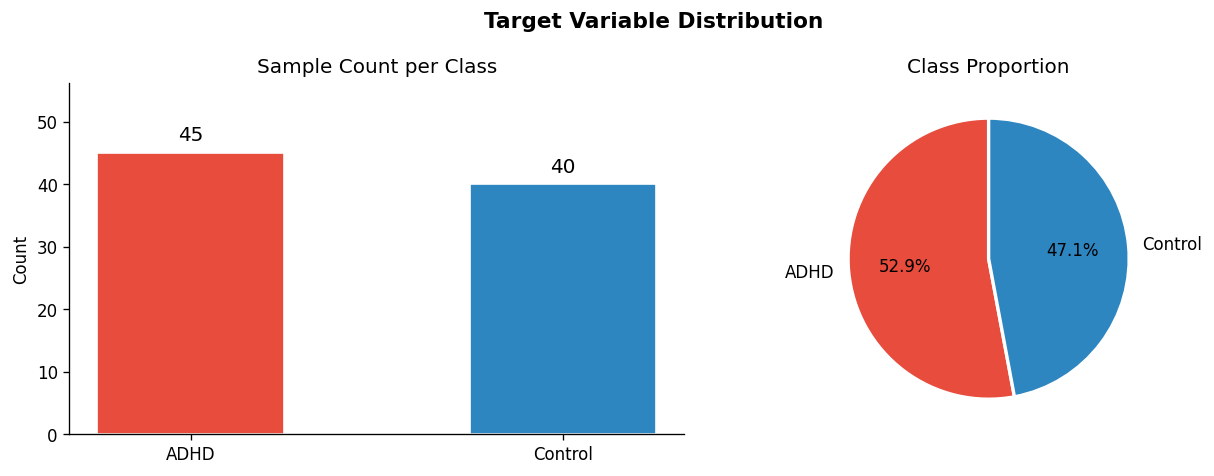

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = data['ADHD_label'].value_counts()

bars = axes[0].bar(counts.index, counts.values,
                   color=[PALETTE[l] for l in counts.index],
                   edgecolor='white', width=0.5)
axes[0].bar_label(bars, fmt='%d', fontsize=12, padding=5)
axes[0].set_title('Sample Count per Class')
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, counts.max() * 1.25)

axes[1].pie(counts.values,
            labels=counts.index,
            colors=[PALETTE[l] for l in counts.index],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Proportion')

plt.suptitle('Target Variable Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

5 | Missing Values

,Count,Percentage (%)
ACC__friedrich_coefficients__coeff_0__m_3__r_30,85,100.00
ACC__friedrich_coefficients__coeff_1__m_3__r_30,85,100.00
ACC__friedrich_coefficients__coeff_2__m_3__r_30,85,100.00
ACC__friedrich_coefficients__coeff_3__m_3__r_30,85,100.00
ACC__max_langevin_fixed_point__m_3__r_30,85,100.00
ACC__query_similarity_count__query_None__threshold_0.0,85,100.00
MED_Analgesics_Opioids,85,100.00
MED_Stimulants,84,98.82
MED_Antipsych,83,97.65
MED_Sleep,83,97.65


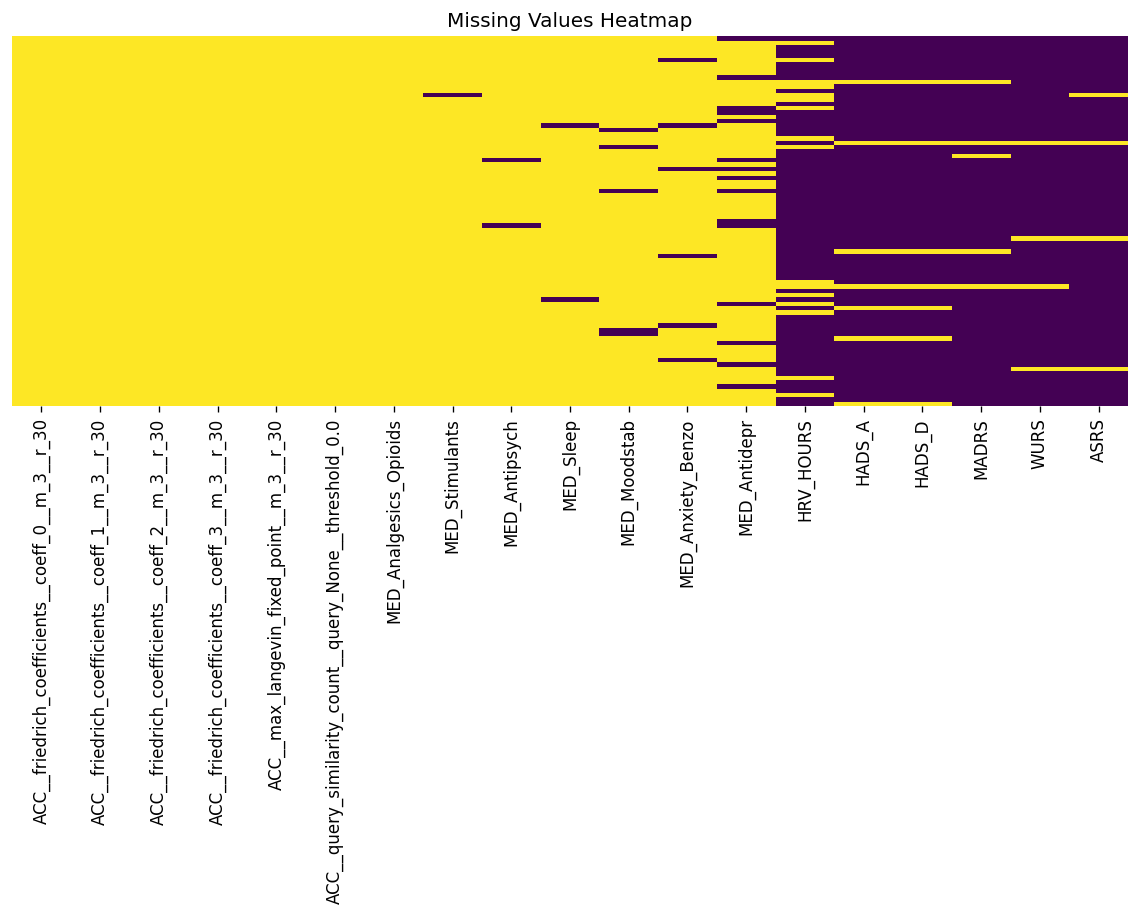

In [ ]:
missing = data[feature_cols].isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print('✓ No missing values detected.')
else:
    missing_pct = (missing / len(data) * 100).round(2)
    display(pd.DataFrame({'Count': missing, 'Percentage (%)': missing_pct}))

    plt.figure(figsize=(12, 4))
    sns.heatmap(data[missing.index].isnull(),
                cbar=False, yticklabels=False, cmap='viridis')
    plt.title('Missing Values Heatmap')
    plt.tight_layout()
    plt.show()

6 | Feature Distributions

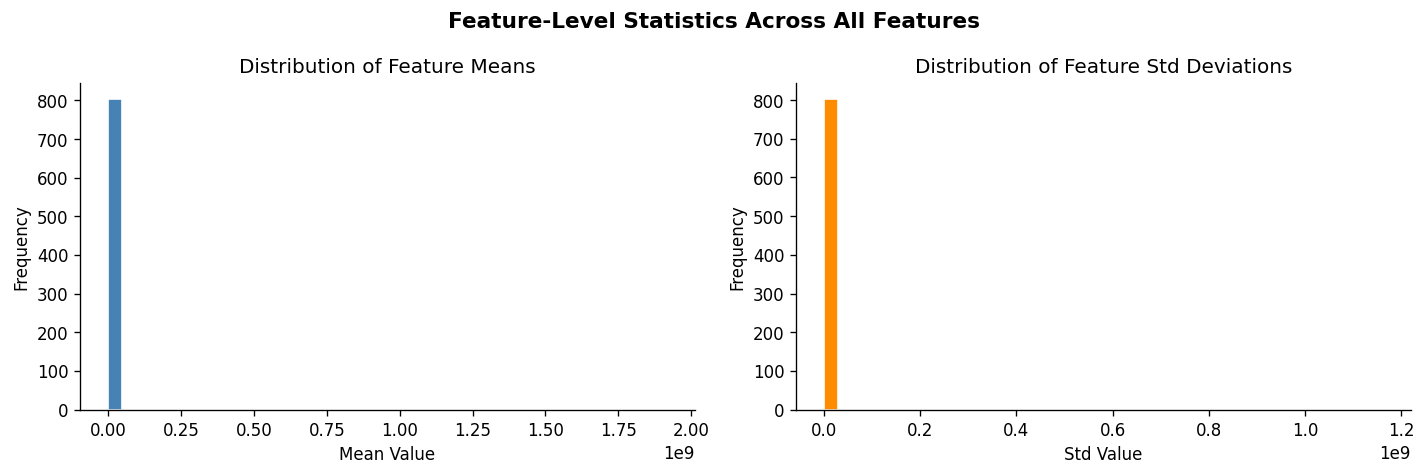

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data[feature_cols].mean().plot(
    kind='hist', bins=40, color='steelblue', edgecolor='white', ax=axes[0])
axes[0].set_title('Distribution of Feature Means')
axes[0].set_xlabel('Mean Value')

data[feature_cols].std().plot(
    kind='hist', bins=40, color='darkorange', edgecolor='white', ax=axes[1])
axes[1].set_title('Distribution of Feature Std Deviations')
axes[1].set_xlabel('Std Value')

plt.suptitle('Feature-Level Statistics Across All Features',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

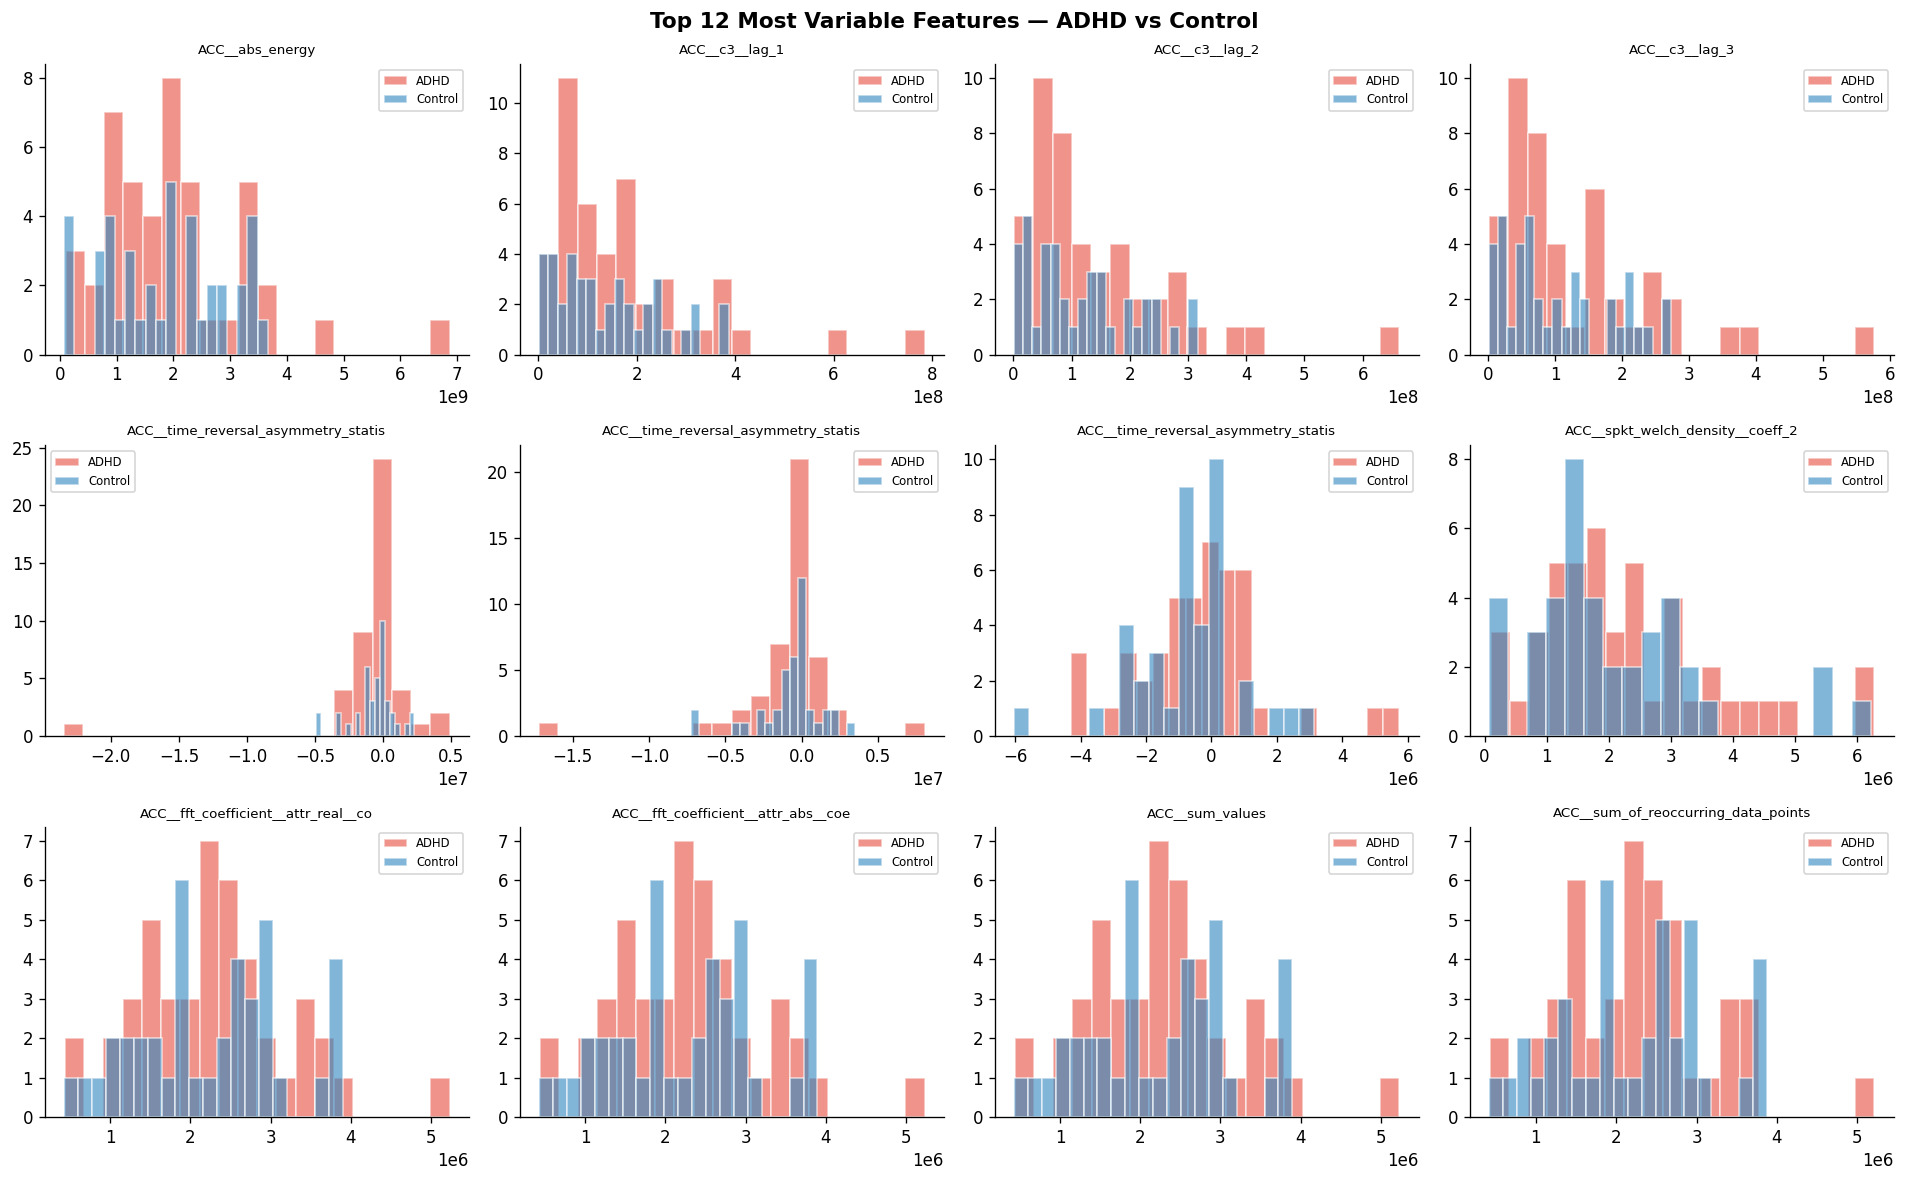

In [ ]:
top_var_cols = data[feature_cols].std().nlargest(12).index.tolist()

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(top_var_cols):
    for label, grp in data.groupby('ADHD_label'):
        axes[i].hist(grp[col].dropna(), bins=20, alpha=0.6,
                     label=label, color=PALETTE[label], edgecolor='white')
    axes[i].set_title(col[:35], fontsize=8)
    axes[i].legend(fontsize=7)

plt.suptitle('Top 12 Most Variable Features — ADHD vs Control',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

7 | Class Separation

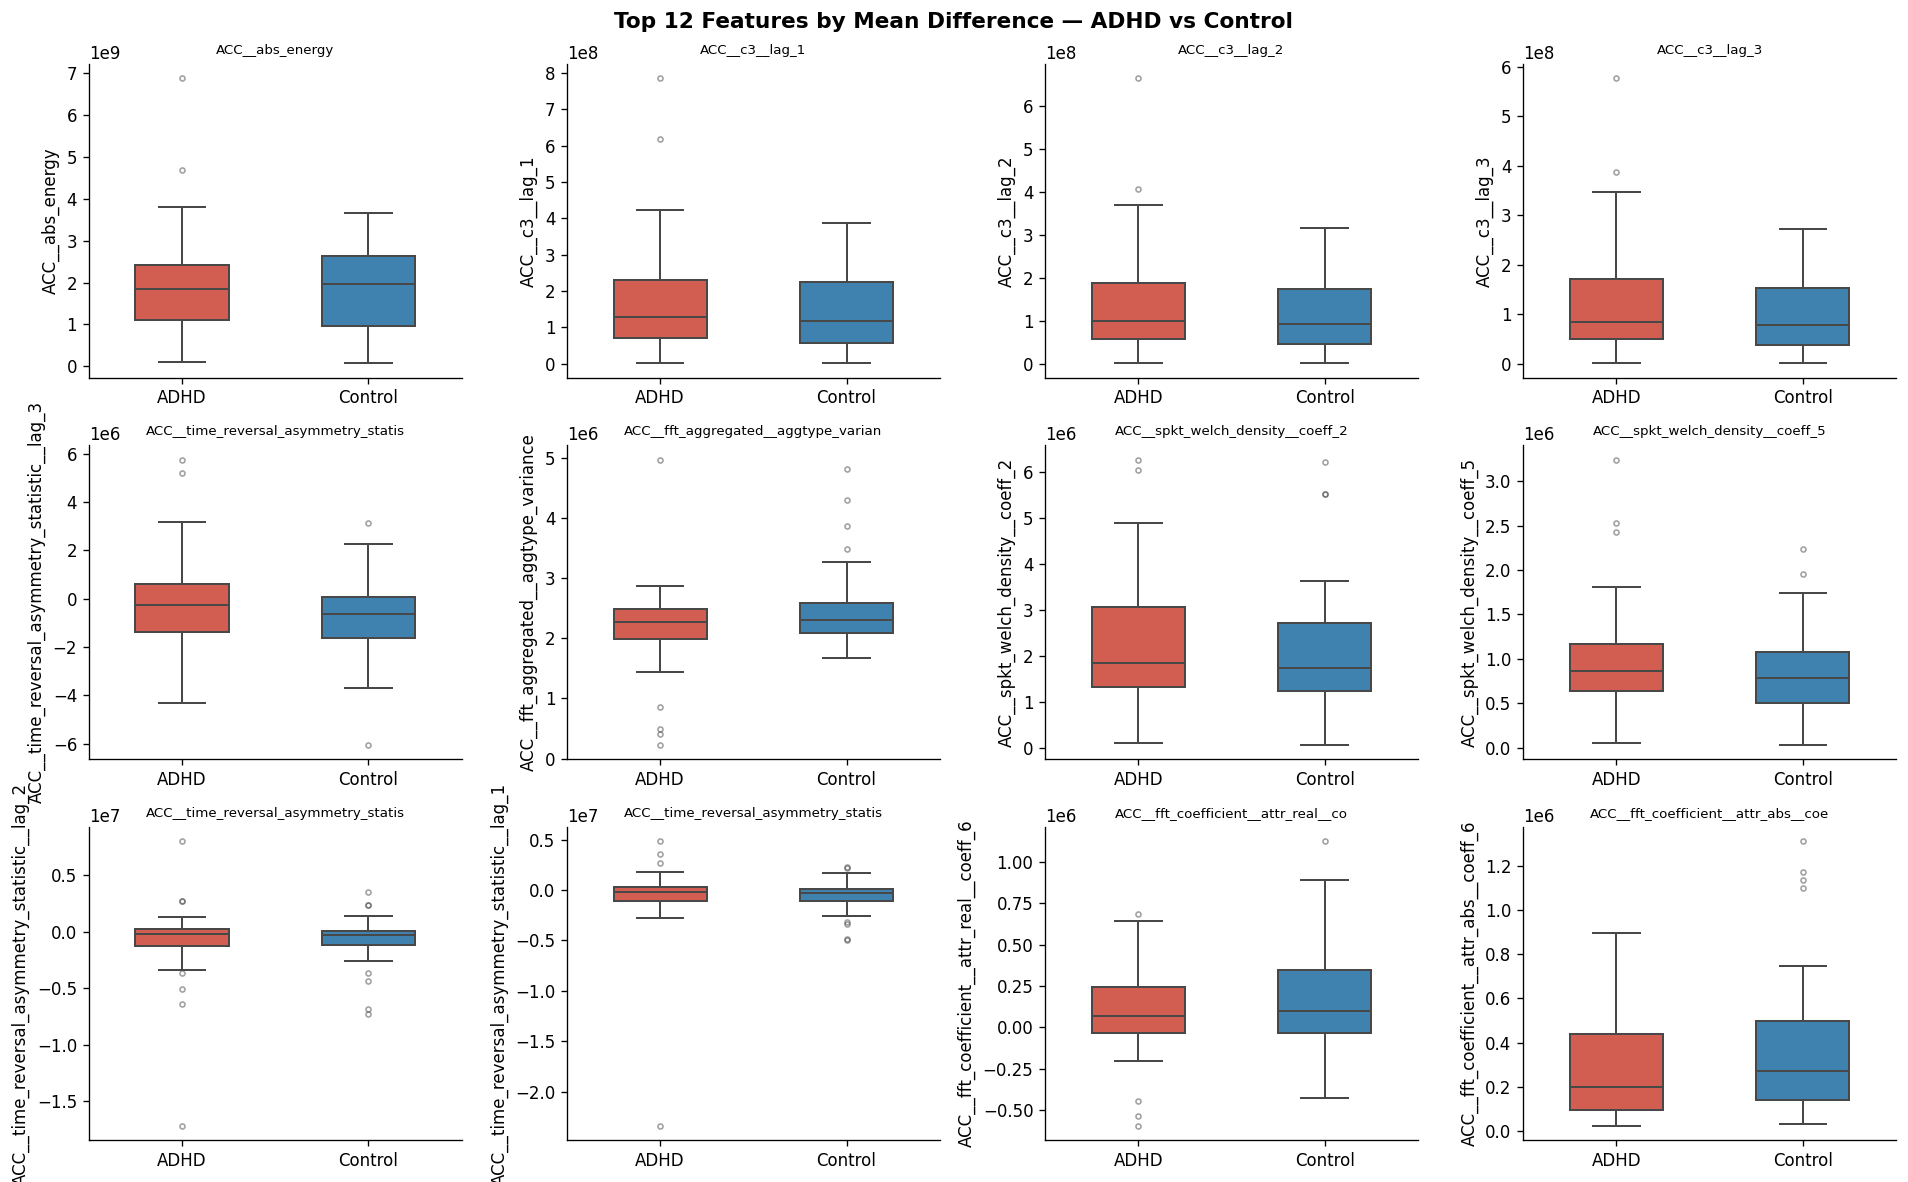

In [ ]:
adhd_mean    = data[data['ADHD']==1][feature_cols].mean()
control_mean = data[data['ADHD']==0][feature_cols].mean()
top_diff     = (adhd_mean - control_mean).abs().nlargest(12).index.tolist()

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(top_diff):
    sns.boxplot(data=data, x='ADHD_label', y=col,
                palette=PALETTE, ax=axes[i],
                width=0.5, linewidth=1.2,
                flierprops={'marker':'o', 'markersize':3, 'alpha':0.5})
    axes[i].set_title(col[:35], fontsize=8)
    axes[i].set_xlabel('')

plt.suptitle('Top 12 Features by Mean Difference — ADHD vs Control',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

8 | Statistical Significance

In [ ]:
pvalues = {
    col: stats.mannwhitneyu(
        data[data['ADHD']==1][col].dropna(),
        data[data['ADHD']==0][col].dropna(),
        alternative='two-sided'
    )[1]
    for col in feature_cols
}

pval_df = (pd.Series(pvalues)
             .sort_values()
             .reset_index()
             .rename(columns={'index': 'Feature', 0: 'p-value'}))
pval_df['Significant'] = pval_df['p-value'] < 0.05

print(f'Significant features (p < 0.05) : {pval_df["Significant"].sum()} / {len(pval_df)}')
display(pval_df.head(20).style.apply(
    lambda x: ['background-color: #fde8e8' if v else '' for v in x == True], axis=1))

Significant features (p < 0.05) : 28 / 816


,Feature,p-value,Significant
0,ADD,0.000000,True
1,WURS,0.000002,True
2,ASRS,0.000003,True
3,ACC__fft_coefficient__attr_real__coeff_53,0.002565,True
4,ACC__fft_coefficient__attr_angle__coeff_28,0.005044,True
5,ACC__fft_coefficient__attr_real__coeff_56,0.006095,True
6,ANXIETY,0.009590,True
7,ACC__fft_coefficient__attr_real__coeff_57,0.010015,True
8,ACC__fft_coefficient__attr_abs__coeff_22,0.010015,True
9,ACC__fft_coefficient__attr_real__coeff_39,0.011653,True


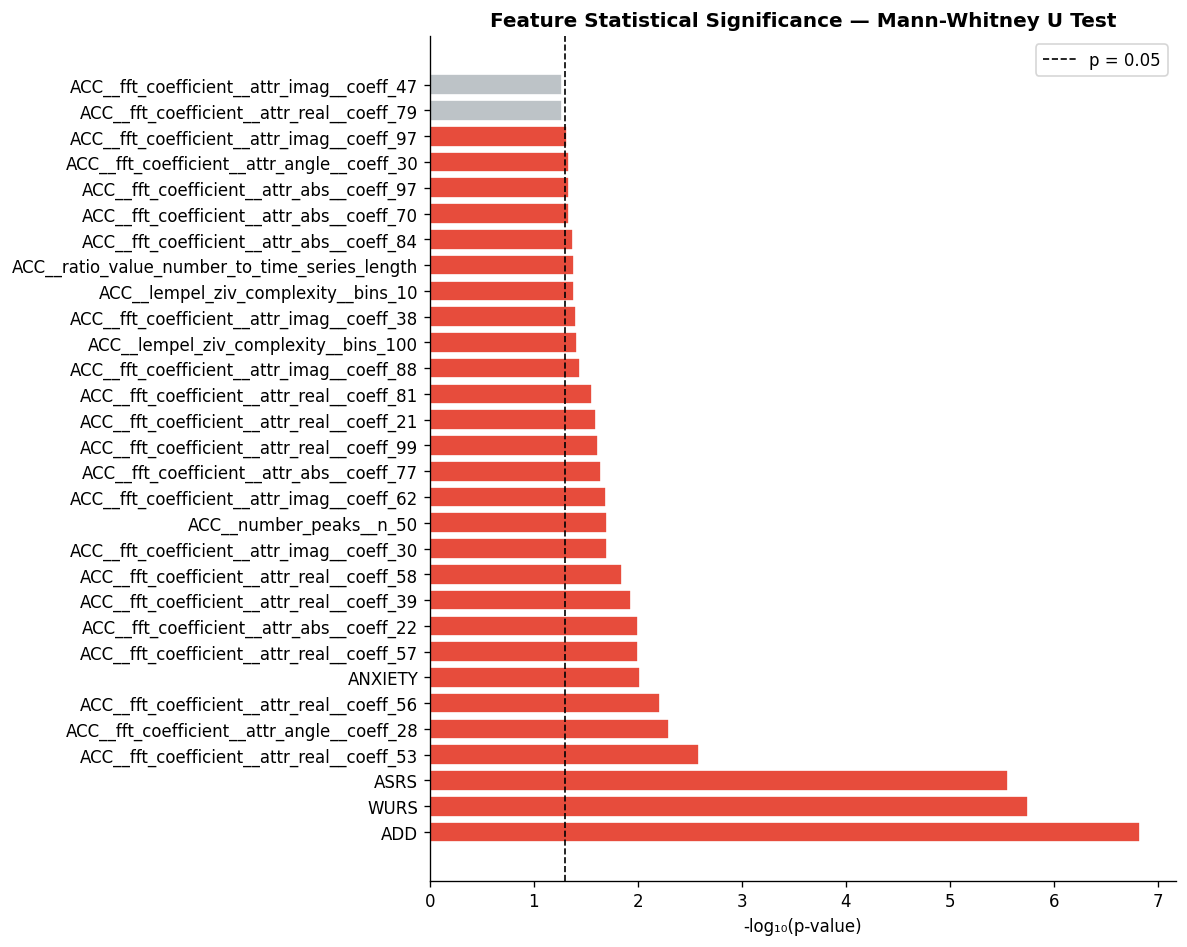

In [ ]:
top30  = pval_df.head(30)
colors = ['#E74C3C' if p < 0.05 else '#BDC3C7' for p in top30['p-value']]

plt.figure(figsize=(10, 8))
plt.barh(top30['Feature'], -np.log10(top30['p-value']),
         color=colors, edgecolor='white')
plt.axvline(-np.log10(0.05), color='black', linestyle='--',
            linewidth=1, label='p = 0.05')
plt.xlabel('-log\u2081\u2080(p-value)')
plt.title('Feature Statistical Significance — Mann-Whitney U Test',
          fontsize=12, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

9 | Correlation Analysis

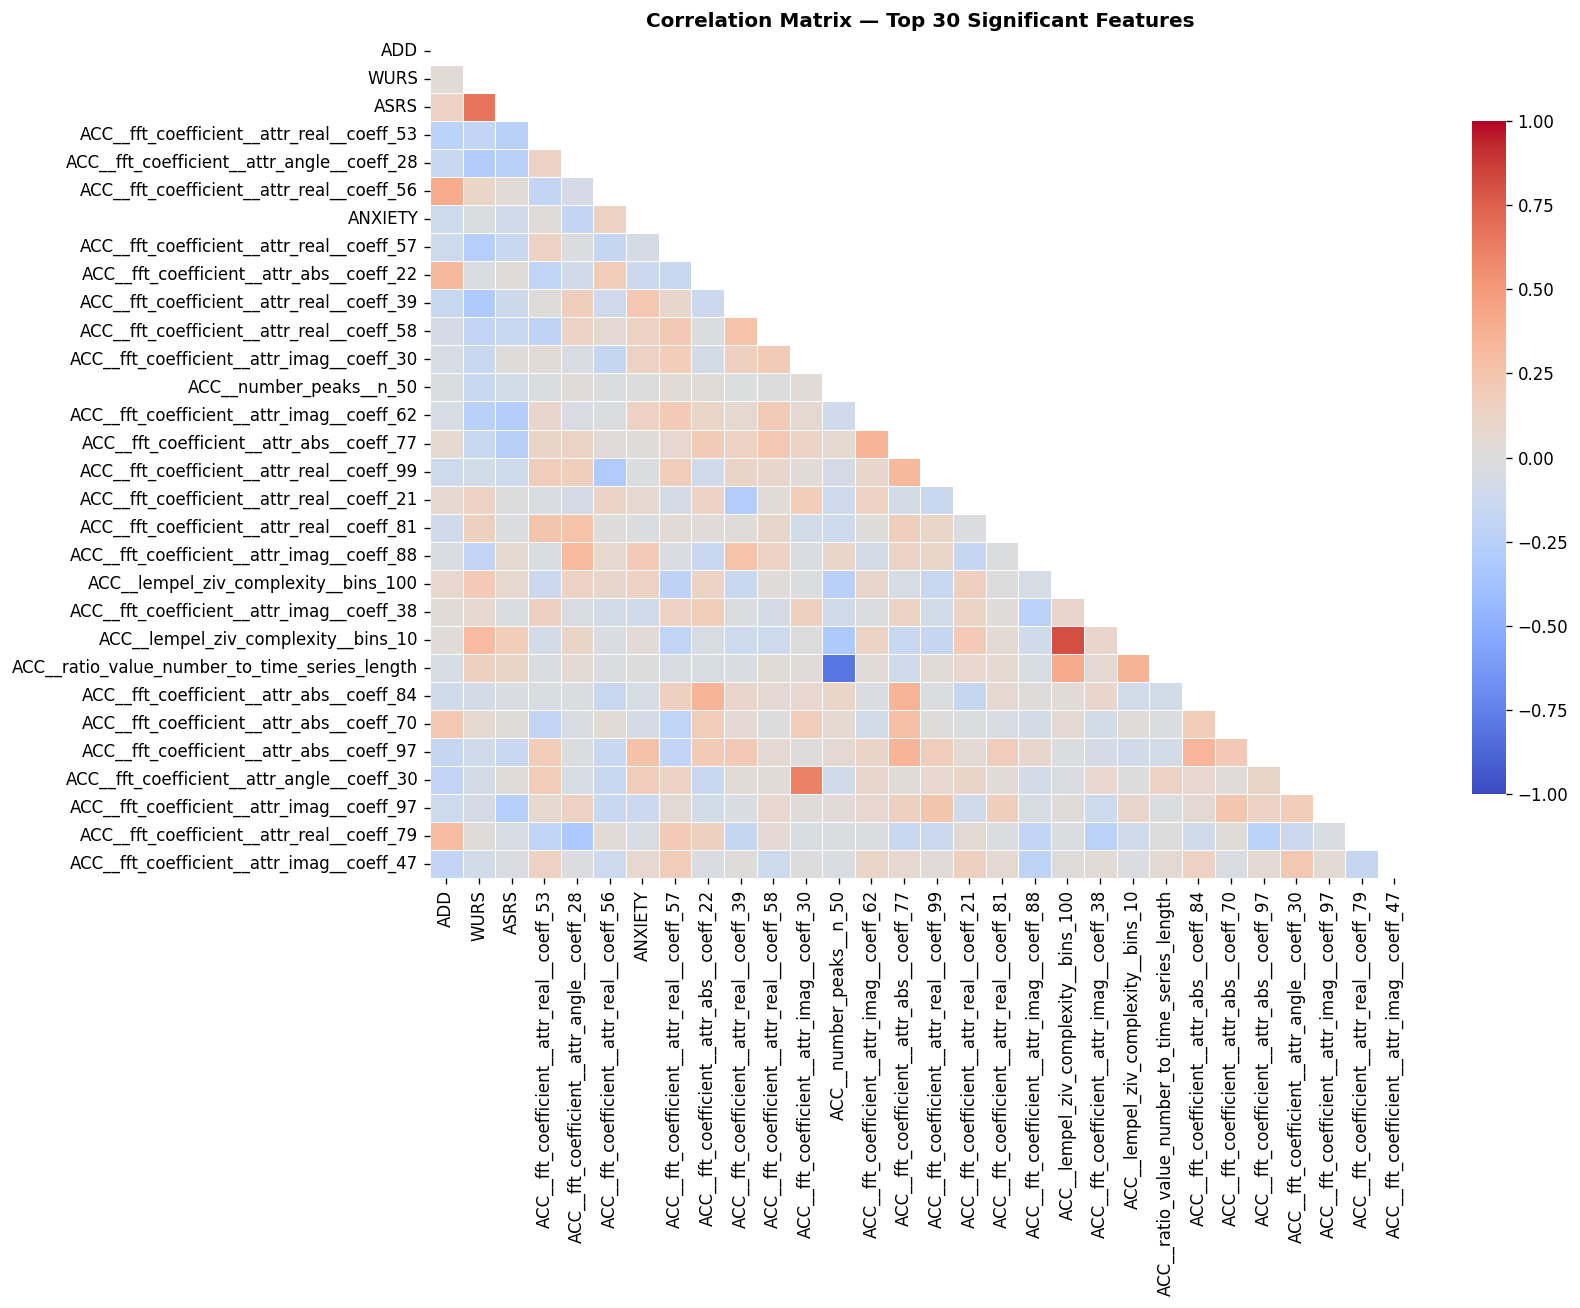

In [ ]:
top30_cols  = pval_df.head(30)['Feature'].tolist()
corr_matrix = data[top30_cols].corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False,
            cmap='coolwarm', center=0, linewidths=0.3,
            vmin=-1, vmax=1, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix — Top 30 Significant Features',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
high_corr = (corr_matrix.abs()
               .where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))
               .stack()
               .reset_index()
               .rename(columns={'level_0': 'Feature A',
                                 'level_1': 'Feature B',
                                 0        : 'Correlation'}))
high_corr = (high_corr[high_corr['Correlation'] > 0.85]
               .sort_values('Correlation', ascending=False))

print(f'Highly correlated pairs (|r| > 0.85) : {len(high_corr)}')
display(high_corr.head(15))

Highly correlated pairs (|r| > 0.85) : 0


,Feature A,Feature B,Correlation


10 | Outlier Detection

Features with outliers : 593
Total outlier cells    : 2391


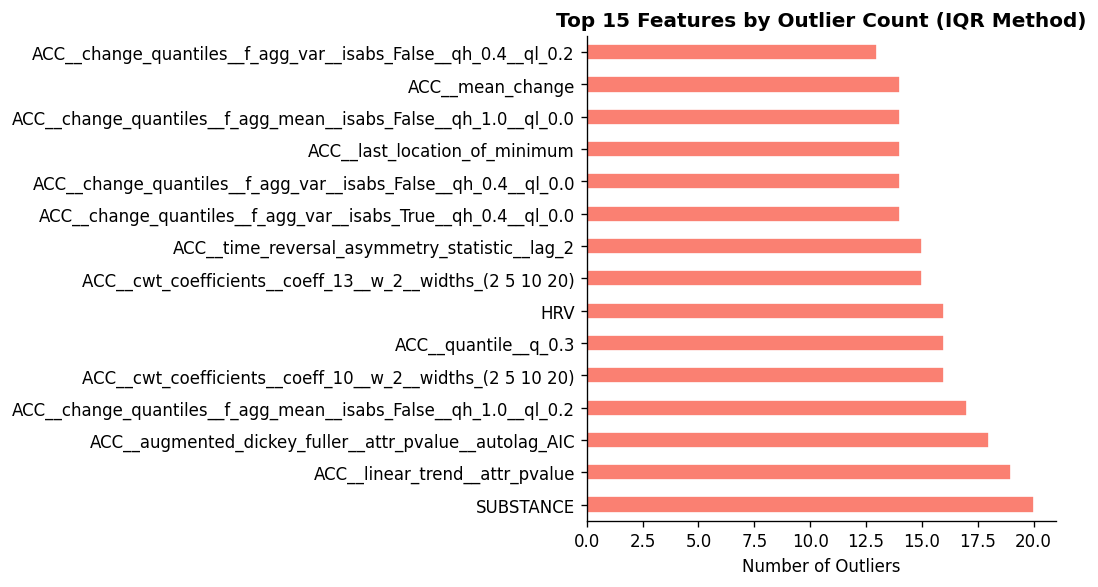

In [ ]:
Q1  = data[feature_cols].quantile(0.25)
Q3  = data[feature_cols].quantile(0.75)
IQR = Q3 - Q1

outlier_counts = (((data[feature_cols] < (Q1 - 1.5*IQR)) |
                   (data[feature_cols] > (Q3 + 1.5*IQR)))
                  .sum()
                  .sort_values(ascending=False))

print(f'Features with outliers : {(outlier_counts > 0).sum()}')
print(f'Total outlier cells    : {outlier_counts.sum()}')

outlier_counts.head(15).plot(
    kind='barh', figsize=(9, 5),
    color='salmon', edgecolor='white')
plt.title('Top 15 Features by Outlier Count (IQR Method)',
          fontsize=12, fontweight='bold')
plt.xlabel('Number of Outliers')
plt.tight_layout()
plt.show()

11 | Demographic Analysis

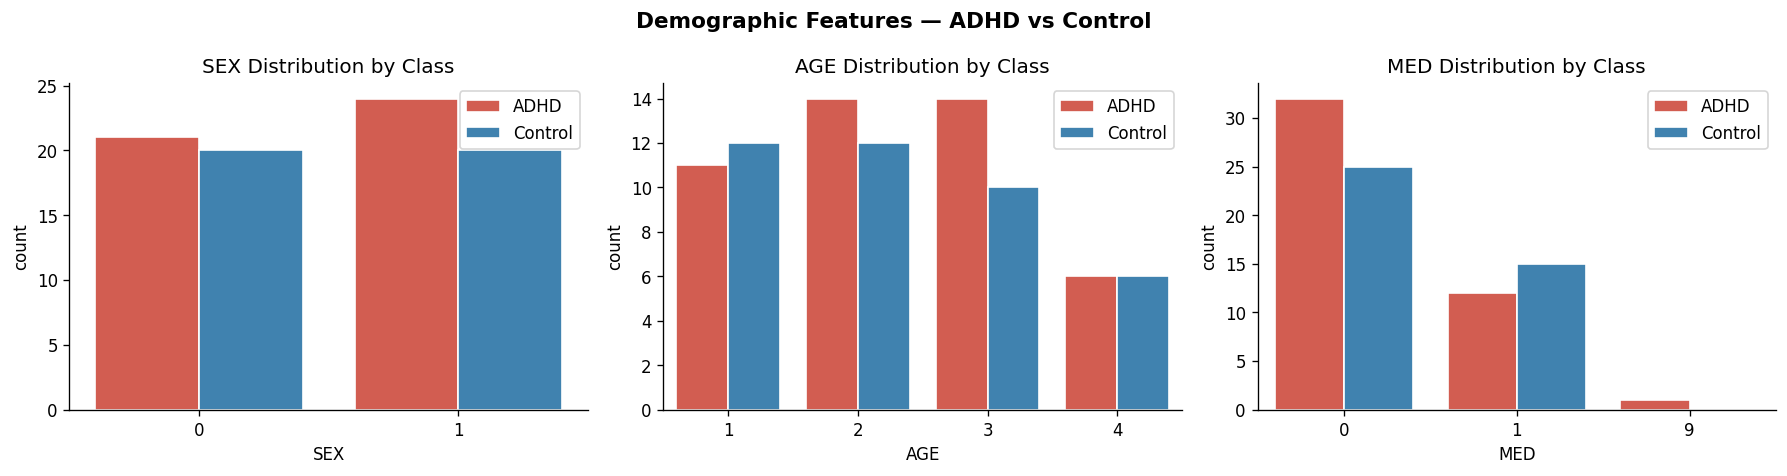

In [ ]:
demo_cols = [c for c in ['SEX', 'AGE', 'MED'] if c in data.columns]

if demo_cols:
    fig, axes = plt.subplots(1, len(demo_cols),
                             figsize=(5 * len(demo_cols), 4))
    if len(demo_cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, demo_cols):
        sns.countplot(data=data, x=col, hue='ADHD_label',
                      palette=PALETTE, ax=ax, edgecolor='white')
        ax.set_title(f'{col} Distribution by Class')
        ax.set_xlabel(col)
        ax.legend(title='')

    plt.suptitle('Demographic Features — ADHD vs Control',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('No demographic columns found.')

12 | EDA Summary

In [ ]:
print('=' * 52)
print('  EDA SUMMARY')
print('=' * 52)
print(f'  Total samples          : {len(data)}')
print(f'  Numeric features       : {len(feature_cols)}')
print(f'  ADHD / Control         : {(data["ADHD"]==1).sum()} / {(data["ADHD"]==0).sum()}')
print(f'  Class balance          : {(data["ADHD"]==1).sum()/len(data)*100:.1f}% ADHD')
print(f'  Missing values         : {data[feature_cols].isnull().sum().sum()}')
print(f'  Significant features   : {pval_df["Significant"].sum()} / {len(pval_df)}')
print(f'  High-corr pairs (>0.85): {len(high_corr)}')
print(f'  Features with outliers : {(outlier_counts > 0).sum()}')
print(f'  Most significant feat  : {pval_df.iloc[0]["Feature"]}')
print(f'  Lowest p-value         : {pval_df.iloc[0]["p-value"]:.2e}')
print('=' * 52)

  EDA SUMMARY
  Total samples          : 85
  Numeric features       : 816
  ADHD / Control         : 45 / 40
  Class balance          : 52.9% ADHD
  Missing values         : 1117
  Significant features   : 28 / 816
  High-corr pairs (>0.85): 0
  Features with outliers : 593
  Most significant feat  : ADD
  Lowest p-value         : 1.46e-07


In [ ]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/EDA.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/EDA.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 9 image(s).
[NbConvertApp] Writing 1703617 bytes to /content/drive/MyDrive/Colab Notebooks/EDA.html
